### <font color = "gold"> Import les librairies requises

In [88]:
# Importer les packages
import pandas as pd
import numpy as np
import plotly.express as px

In [89]:
# Supprimer les warnings
import warnings
warnings.filterwarnings('ignore')

### <font color = "gold"> Importer et lire les données

In [90]:
# Importer les données
df = pd.read_csv('/content/sample_data/pricerunner_aggregate.csv')

#### Description des variables du jeu de données "Télécommunications"

Ce jeu de données provient de PriceRunner, une plateforme de comparaison de produits très répandue. Il comprend 35 311 offres de produits réparties en 10 catégories et proposées par 306 marchands différents. Ce jeu de données constitue un terrain idéal pour l'évaluation des algorithmes de classification, de clustering et de correspondance d'entités.




In [91]:
# Afficher les données
df.head()

,Product ID,Product Title,Merchant ID,Cluster ID,Cluster Label,Category ID,Category Label
0,1,apple iphone 8 plus 64gb silver,1,1,Apple iPhone 8 Plus 64GB,2612,Mobile Phones
1,2,apple iphone 8 plus 64 gb spacegrau,2,1,Apple iPhone 8 Plus 64GB,2612,Mobile Phones
2,3,apple mq8n2b/a iphone 8 plus 64gb 5.5 12mp sim...,3,1,Apple iPhone 8 Plus 64GB,2612,Mobile Phones
3,4,apple iphone 8 plus 64gb space grey,4,1,Apple iPhone 8 Plus 64GB,2612,Mobile Phones
4,5,apple iphone 8 plus gold 5.5 64gb 4g unlocked ...,5,1,Apple iPhone 8 Plus 64GB,2612,Mobile Phones


####  <font color = "gold" > Explorer les données

In [92]:
# Dimension des données
df.shape

(35311, 7)

In [93]:
#infos
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 35311 entries, 0 to 35310
Data columns (total 7 columns):
 #   Column           Non-Null Count  Dtype 
---  ------           --------------  ----- 
 0   Product ID       35311 non-null  int64 
 1   Product Title    35311 non-null  object
 2    Merchant ID     35311 non-null  int64 
 3    Cluster ID      35311 non-null  int64 
 4    Cluster Label   35311 non-null  object
 5    Category ID     35311 non-null  int64 
 6    Category Label  35311 non-null  object
dtypes: int64(4), object(3)
memory usage: 1.9+ MB


In [94]:
# Décrire les données
df.describe()

,Product ID,Merchant ID,Cluster ID,Category ID
count,35311.000000,35311.000000,35311.000000,35311.000000
mean,26150.800176,120.501883,30110.687633,2618.142930
std,13498.191220,117.045557,18410.265642,3.600708
min,1.000000,1.000000,1.000000,2612.000000
25%,14958.500000,17.000000,6123.000000,2615.000000
50%,27614.000000,75.000000,40630.000000,2619.000000
75%,37508.500000,253.000000,44059.000000,2622.000000
max,47358.000000,371.000000,47525.000000,2623.000000


In [95]:
df["Product ID"].is_unique

True

### <font color='gold'> Preparation des données

In [96]:
# renommer les index en toute sécurité
df = df.reset_index(drop=True)
df.index = ['Produit' + str(i+1) for i in range(len(df))]
df.head()

,Product ID,Product Title,Merchant ID,Cluster ID,Cluster Label,Category ID,Category Label
Produit1,1,apple iphone 8 plus 64gb silver,1,1,Apple iPhone 8 Plus 64GB,2612,Mobile Phones
Produit2,2,apple iphone 8 plus 64 gb spacegrau,2,1,Apple iPhone 8 Plus 64GB,2612,Mobile Phones
Produit3,3,apple mq8n2b/a iphone 8 plus 64gb 5.5 12mp sim...,3,1,Apple iPhone 8 Plus 64GB,2612,Mobile Phones
Produit4,4,apple iphone 8 plus 64gb space grey,4,1,Apple iPhone 8 Plus 64GB,2612,Mobile Phones
Produit5,5,apple iphone 8 plus gold 5.5 64gb 4g unlocked ...,5,1,Apple iPhone 8 Plus 64GB,2612,Mobile Phones


In [97]:
# Sélectionner et encoder les colonnes catégorielles (textuelles)
from sklearn.preprocessing import LabelEncoder

cat_cols = df.select_dtypes(include=['object']).columns
encoder = LabelEncoder()

for col in cat_cols:
    df[col] = encoder.fit_transform(df[col])

df.head()

,Product ID,Product Title,Merchant ID,Cluster ID,Cluster Label,Category ID,Category Label
Produit1,1,2561,1,1,909,2612,7
Produit2,2,2559,2,1,909,2612,7
Produit3,3,2656,3,1,909,2612,7
Produit4,4,2563,4,1,909,2612,7
Produit5,5,2565,5,1,909,2612,7


In [98]:
# Données en format matriciel (mises à jour après encodage)
x = df.values
x[:5]

array([[   1, 2561,    1,    1,  909, 2612,    7],
       [   2, 2559,    2,    1,  909, 2612,    7],
       [   3, 2656,    3,    1,  909, 2612,    7],
       [   4, 2563,    4,    1,  909, 2612,    7],
       [   5, 2565,    5,    1,  909, 2612,    7]])

In [99]:
# Importer Normalizer
from sklearn.preprocessing import Normalizer
# Instantier le normaliseur
scaler = Normalizer()
# Normaliser les données
x = scaler.fit_transform(x)
x[:5]

array([[2.65301478e-04, 6.79437086e-01, 2.65301478e-04, 2.65301478e-04,
        2.41159044e-01, 6.92967461e-01, 1.85711035e-03],
       [5.30794161e-04, 6.79151129e-01, 5.30794161e-04, 2.65397081e-04,
        2.41245946e-01, 6.93217175e-01, 1.85777956e-03],
       [7.82374873e-04, 6.92662554e-01, 7.82374873e-04, 2.60791624e-04,
        2.37059587e-01, 6.81187723e-01, 1.82554137e-03],
       [1.06082227e-03, 6.79721872e-01, 1.06082227e-03, 2.65205569e-04,
        2.41071862e-01, 6.92716945e-01, 1.85643898e-03],
       [1.32554900e-03, 6.80006638e-01, 1.32554900e-03, 2.65109800e-04,
        2.40984808e-01, 6.92466798e-01, 1.85576860e-03]])

#### <font color = "gold"> Appliquer une ACP

In [100]:
from matplotlib.pyplot import draw_if_interactive
# Importer PCA
from sklearn.decomposition import PCA
#Instantier le modèle PCA avec n_components = 2
pca=PCA(n_components=2)
# Matrice des 2 composantes
features_pca=pca.fit_transform(x)
# Dataframe
df_pca = pd.DataFrame(features_pca)

In [101]:
# Part de variance des 2 composantes
round(sum(pca.explained_variance_ratio_*100),2)

np.float64(91.24)

### <font color='gold'> Kmeans

In [102]:
# Importer KMeans
from sklearn.cluster import KMeans

##### <font color = "bisque"> La méthode elbow(coude)

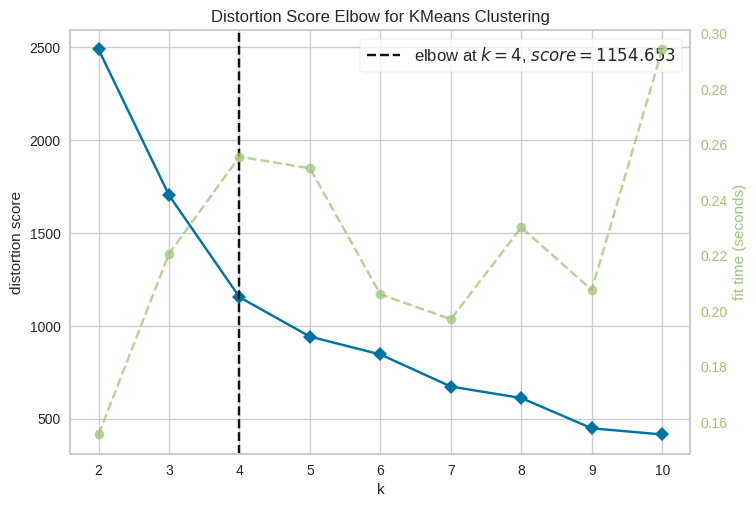

<Axes: title={'center': 'Distortion Score Elbow for KMeans Clustering'}, xlabel='k', ylabel='distortion score'>

In [103]:
# importer KELbowVisualizer
from yellowbrick.cluster import KElbowVisualizer
# Instantier le modèle kmeans
kmeans_model = KMeans(init = 'random', max_iter=500)
# Instantier KELbowVisualizer
Elbow_M = KElbowVisualizer(kmeans_model, k=10)
# Entrainement
Elbow_M.fit(x)
# Visualiser l'elbow
Elbow_M.show()

#### <font color = "bisque"> Appliquer Kmeans en utilisant le k optimal

In [104]:
# instantier le modèle
kmeans_model = KMeans(n_clusters = 3, init = 'random', max_iter = 500)
# Entrainer le modèle
kmeans_model.fit(x)

KMeans(init='random', max_iter=500, n_clusters=3)

#### <font color='teal'> Prédiction

In [105]:
# Prediction de la partition des données
kmeans_partition = kmeans_model.predict(x)
# Afficher la partition
kmeans_partition[: 100]

array([1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1], dtype=int32)

In [106]:
# Nombre d'observations dans chaque classe
val = pd.Series(kmeans_partition).value_counts()
val

,count
0,23812
1,6267
2,5232


In [107]:
# Function de visualisation du diagramme en barre des nombres d'observations.
def bar_plot(val):
  fig = px.bar(x = val.index.astype(str), y = val.values, color = val.index.astype(str), text_auto = True)
  fig.show()

In [108]:
# visualiser le diagramme des nombres d'observations
bar_plot(val)

#### <font color = "bisque"> Visualiser les classes prédictes par Kmeans

In [109]:
# Visualiser les classes suivant les deux composantes en utilisant plotly.express
fig = px.scatter(df_pca, x = 0, y = 1, color = kmeans_partition.astype(str), labels={'0': 'PC1', '1': 'PC2'})
fig.show()

<font color = "bisque">Indice de silhouette value de la partition du Kmeans

In [110]:
# Importer silhouette score
from sklearn.metrics import silhouette_score
# Indice de Silhouette value
sil_kmeans = silhouette_score(x, kmeans_partition)
print(f"Silhouette score : {sil_kmeans }")

Silhouette score : 0.5788095363411255


In [111]:
# Les graines de chaque classes
clusters_names = []
for i in range(4):
  clusters_names.append(list(df.index[kmeans_partition == i]))

In [112]:
# Afficher les graines de la classe 0
print(clusters_names[3])

[]


### <font color='gold'> CAH

In [113]:
# Importer linkage et dendrogram
from scipy.cluster.hierarchy import  linkage, dendrogram

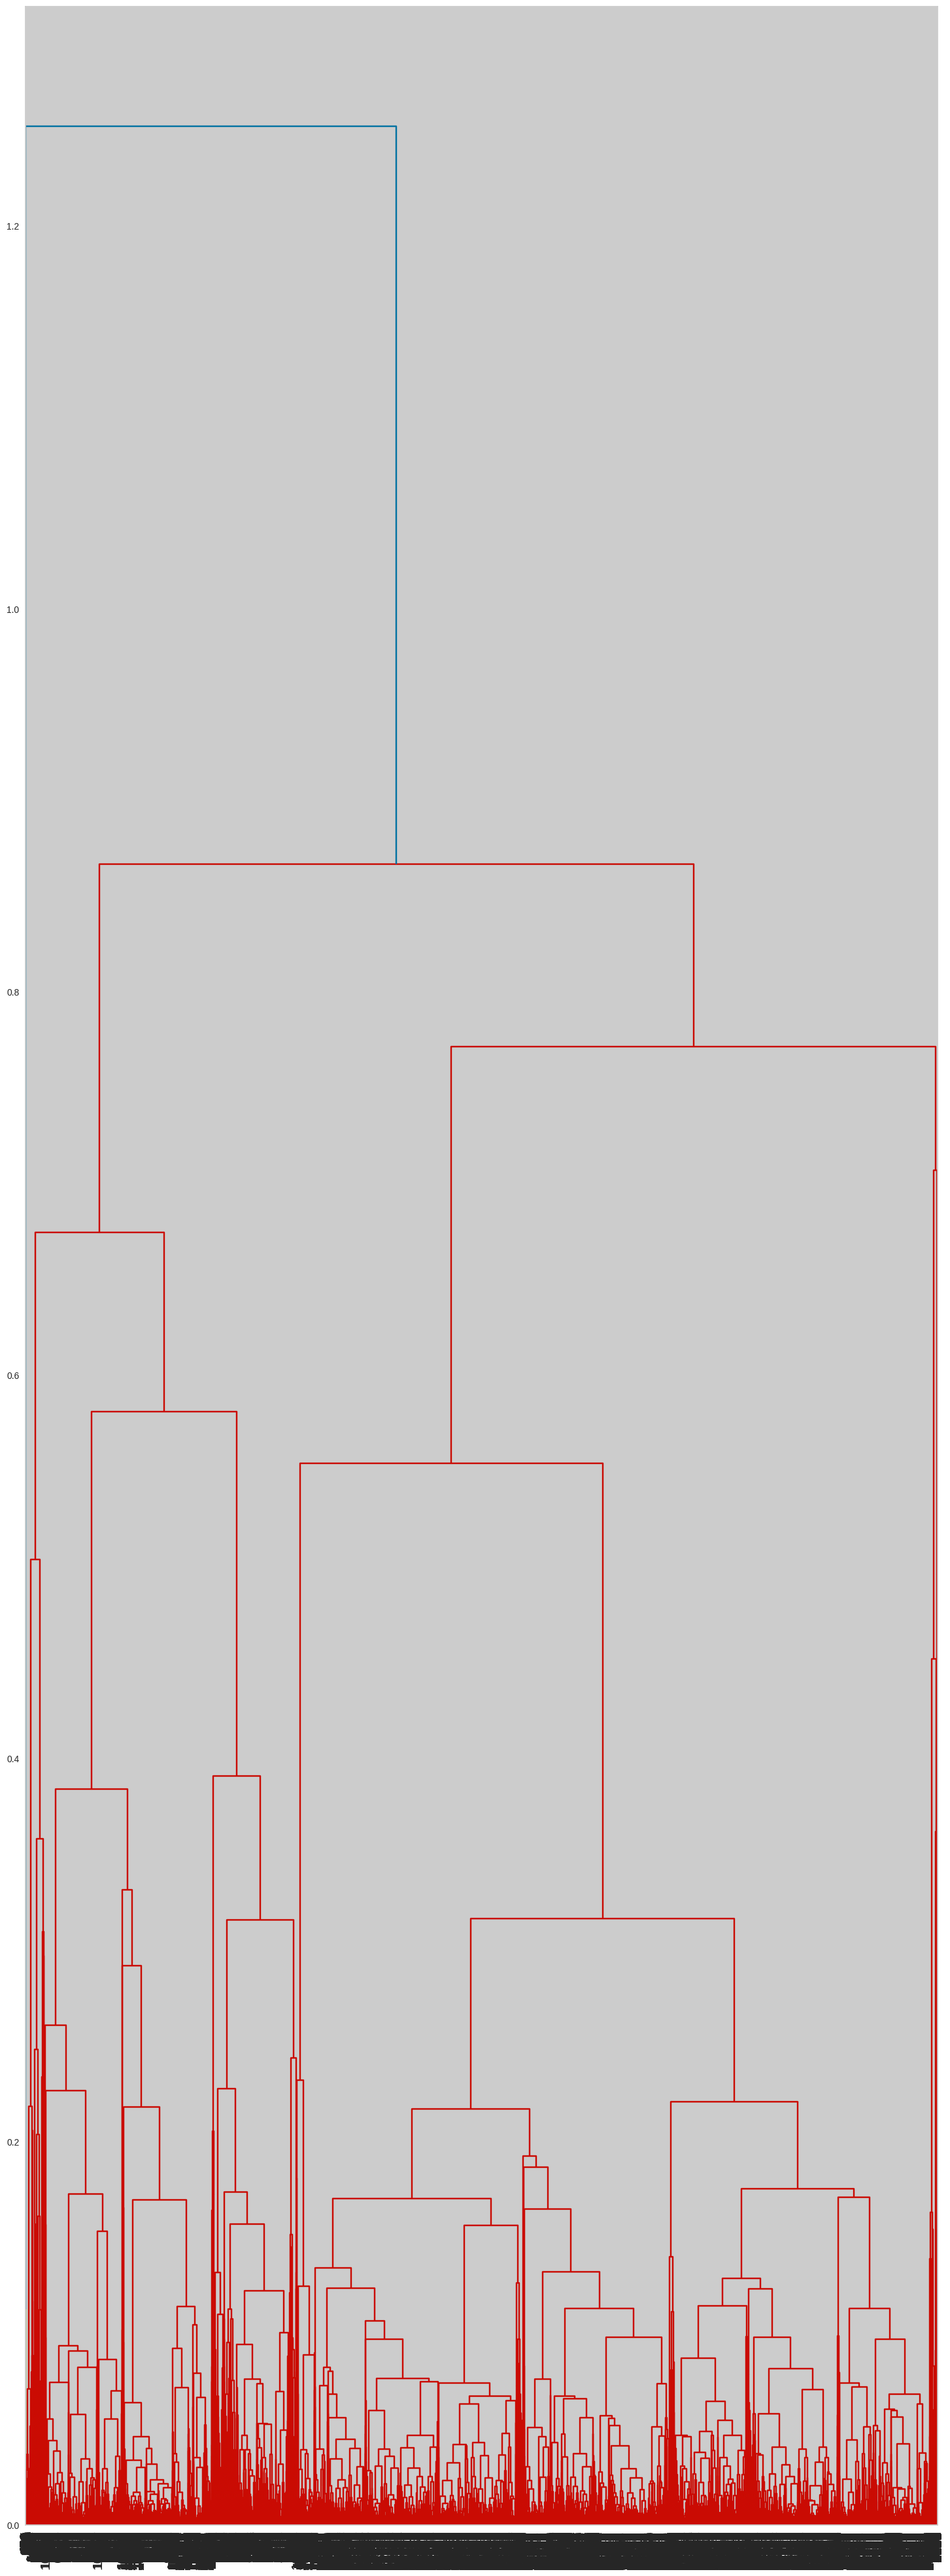

In [114]:
# Visualiser le dendrograme
import matplotlib.pyplot as plt
Z = linkage(x, 'average')# matrice des liaisons
plt.figure(figsize=(18, 50))
dendro = dendrogram(Z, leaf_font_size=15, orientation = 'top')

In [115]:
from sklearn.cluster import AgglomerativeClustering
# Initier AgglomerativeClustering
cah_model = AgglomerativeClustering(n_clusters =2, linkage = 'average')
# Entrainer le modèle
cah_model.fit(x)

AgglomerativeClustering(linkage='average')

In [116]:
# Prédire la partition des données
cah_partition = cah_model.fit_predict(x)
# Afficher la partition
cah_partition[:100]

array([0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0])

In [117]:
# Nombre d'observations dans chaque classe
val1  = pd.Series(cah_partition).value_counts()
val1

,count
0,35305
1,6


In [118]:
# Diagramme en barre des nombres d'observations
fig = px.bar(x = val1.index.astype(str), y = val1.values, color = val1.index.astype(str))
fig.show()

In [119]:
# Visualiser les classes de la CAH sur le plan de l'ACP
fig = px.scatter(df_pca, x = 0, y = 1, color = cah_partition.astype(str), labels={'0': 'PC1', '1': 'PC2'})
fig.show()

In [120]:
# Silhouette score
sil_cah = silhouette_score(x, cah_partition)
print(f"La silhouette score :{sil_cah}")

La silhouette score :0.5667665098083047


In [121]:
# Diagrammes en barre des silhouettes
Model_Names = ['KMEANS', 'CAH']
sil = [sil_kmeans, sil_cah]
fig = px.bar(x= Model_Names, y = sil, color = Model_Names, text_auto = True)
fig.show()

In [122]:
# les indidivus
cluster_names = []
for i in range(2):
  cluster_names.append(list(df.index[kmeans_partition == i]))

In [123]:
# Les individus de la classe 0
print(cluster_names[0])

['Produit7412', 'Produit10521', 'Produit11444', 'Produit11478', 'Produit11484', 'Produit11485', 'Produit11487', 'Produit11488', 'Produit11508', 'Produit11509', 'Produit11510', 'Produit11511', 'Produit11512', 'Produit11513', 'Produit11514', 'Produit11515', 'Produit11516', 'Produit11517', 'Produit11518', 'Produit11519', 'Produit11520', 'Produit11521', 'Produit11522', 'Produit11523', 'Produit11524', 'Produit11525', 'Produit11526', 'Produit11527', 'Produit11528', 'Produit11529', 'Produit11530', 'Produit11531', 'Produit11532', 'Produit11533', 'Produit11534', 'Produit11535', 'Produit11536', 'Produit11537', 'Produit11538', 'Produit11539', 'Produit11540', 'Produit11541', 'Produit11542', 'Produit11543', 'Produit11544', 'Produit11545', 'Produit11546', 'Produit11547', 'Produit11548', 'Produit11549', 'Produit11550', 'Produit11551', 'Produit11552', 'Produit11553', 'Produit11554', 'Produit11555', 'Produit11556', 'Produit11557', 'Produit11558', 'Produit11559', 'Produit11560', 'Produit11561', 'Produit

### <font color = "gold"> Interpréter les classes

Avant de déployer le modèle, il faut savoir **ce que représente chaque classe**, pour afficher un
message compréhensible par l'utilisateur final. On regarde le profil moyen de chaque classe.

In [124]:
# Profil moyen de chaque classe
profil = df.groupby(kmeans_partition).mean().round(3)
profil

,Product ID,Product Title,Merchant ID,Cluster ID,Cluster Label,Category ID,Category Label
0,34085.845,15200.609,156.927,42777.871,6257.657,2620.324,4.475
1,5917.540,19869.895,39.707,2237.434,7873.723,2612.816,7.355
2,14272.465,10653.798,51.500,5846.678,4695.012,2614.596,2.098


In [125]:
# Noms des classes
noms_classes = {
    0: "Produit standard",
    1: "Produit spécial",
}

### <font color = "gold"> Préparer le meilleur modèle (CAH) pour le déploiement

`AgglomerativeClustering` n'a pas de méthode `predict()` : il ne sait pas classer une **nouvelle** graine.
On entraîne donc un `NearestCentroid` sur les classes trouvées par la CAH : une nouvelle graine est affectée
à la classe dont le **centroïde est le plus proche**. Ce modèle reproduit la partition de la CAH.

In [126]:
from sklearn.neighbors import NearestCentroid
# Instantier le modèle des centroïdes
model = NearestCentroid()
# Entrainer sur les classes trouvées par KMEANS
model.fit(x, kmeans_partition)
# Vérifier que le modèle retrouve bien la partition de KMEANS
print("Concordance avec KMEANS :", (model.predict(x) == kmeans_partition).mean())

Concordance avec KMEANS : 0.9996884823426128


In [127]:
# Test rapide sur le première produit
produit = scaler.transform(df.iloc[[0]])
print("Classe prédite         :", noms_classes[model.predict(produit)[0]])
print("Classe réelle de KMEANS:", noms_classes[kmeans_partition[0]])

Classe prédite         : Produit spécial
Classe réelle de KMEANS: Produit spécial


### <font color = "gold"> Sauvegarde des modèles (joblib)

On enregistre le normaliseur, l'ACP et le modèle dans le même dossier que les données.
L'application Streamlit `app_wheat.py` les chargera.

In [128]:
import os
# Créer le dossier s'il n'existe pas
os.makedirs('/content/model', exist_ok=True)

In [129]:
import joblib
import sklearn
# Dossier de sauvegarde
# Enregistrer le normaliseur, l'ACP et le modèle
joblib.dump(scaler, '/content/model/scaler_product.joblib')
joblib.dump(pca, '/content/model/pca_product.joblib')
joblib.dump(model, '/content/model/model_product.joblib')
# Version de scikit-learn à installer aussi pour Streamlit
print("scikit-learn", sklearn.__version__)

scikit-learn 1.6.1
